In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from hac.lc2mesh.data import create_ellipsoidal_prior_mesh, load_training_template_mesh
from hac.lc2mesh.model import LightcurveToMesh
from hac.lc2mesh.utils import (
    build_fixed_subset,
    chamfer_distance,
    deformation_tv_regularization,
    differentiable_voxel_measure,
    edge_length_regularization,
    laplacian_regularization,
    resample_target_to_prior_directions,
    set_seed,
    setup_device,
    soft_correspondence_normal_loss,
    vertex_normals_from_faces,
)
from hac.lc2mesh.visualization import plot_interactive_mesh

SEED = 42
set_seed(SEED)

TARGET_GPU_ID = 1
device = setup_device(TARGET_GPU_ID)


Device: cuda:1 (Tesla V100-SXM2-32GB)
Visible CUDA devices: 8


## 1) Mesh Initialization


Theory: The initial shape prior is a geodesic icosphere scaled into an ellipsoid with semi-axes $(R, R, 1)$, matching the HAC cylinder constraint $D(0,R) \times [-1,1]$. This provides a physically valid starting mesh and fixed topology for deformation.


Implementation and test goals:


- Build the icosphere with configurable subdivision level $N$.


- Scale vertices by $(R, R, 1)$.


- Plot the mesh.


- Assert that radial and vertical bounds satisfy the cylinder prior.

In [2]:
ASTEROID_ID = 1
N_SUBDIVISIONS = 4

prior_bundle = create_ellipsoidal_prior_mesh(
    asteroid_id=ASTEROID_ID,
    subdivisions=N_SUBDIVISIONS,
    device=device,
 )

R_CYLINDER = prior_bundle["R_CYLINDER"]
normals = prior_bundle["normals"]
sigma = prior_bundle["sigma"]
n_facets = prior_bundle["n_facets"]
radial_max = prior_bundle["radial_max"]
z_min = prior_bundle["z_min"]
z_max = prior_bundle["z_max"]

prior_vertices_np = prior_bundle["prior_vertices_np"]
prior_faces_np = prior_bundle["prior_faces_np"]
prior_vertices_t = prior_bundle["prior_vertices_t"]
prior_faces_t = prior_bundle["prior_faces_t"]
prior_edges_np = prior_bundle["prior_edges_np"]
prior_edge_index_np = prior_bundle["prior_edge_index_np"]
prior_edges_t = prior_bundle["prior_edges_t"]
prior_edge_index_t = prior_bundle["prior_edge_index_t"]
prior_vertex_neighbors = prior_bundle["prior_vertex_neighbors"]
prior_vertices_batch = prior_bundle["prior_vertices_batch"]

print(f"Ellipsoidal prior (R={R_CYLINDER}): {len(prior_vertices_np)} vertices, {n_facets} faces")
print(f"Total surface area: {sigma.sum():.4f}")
print(
    f"Vertex ranges - x: [{prior_vertices_np[:,0].min():.3f}, {prior_vertices_np[:,0].max():.3f}]  "
    f"y: [{prior_vertices_np[:,1].min():.3f}, {prior_vertices_np[:,1].max():.3f}]  "
    f"z: [{prior_vertices_np[:,2].min():.3f}, {prior_vertices_np[:,2].max():.3f}]"
)

assert radial_max <= R_CYLINDER + 1e-4, "Radial extent violates cylinder bound."
assert z_min >= -1.0 - 1e-4 and z_max <= 1.0 + 1e-4, "z extent violates [-1, 1]."
print("Step 1 test passed: mesh bounds satisfy cylinder constraint.")

# Interactive rotatable 3D mesh (same utility as inr_forward_train.ipynb).
fig_prior = plot_interactive_mesh(
    vertices=prior_vertices_np,
    faces=prior_faces_np,
    title=f"Asteroid {ASTEROID_ID}: ellipsoidal prior (R={R_CYLINDER}) - {n_facets} faces",
    mesh_color="#73b7ff",
    show_edges=False,
)
fig_prior.show()

print(f"Prior tensor shape: {prior_vertices_batch.shape}, faces shape: {prior_faces_t.shape}")


Ellipsoidal prior (R=1.12): 2562 vertices, 5120 faces
Total surface area: 14.6327
Vertex ranges - x: [-1.120, 1.120]  y: [-1.120, 1.120]  z: [-1.000, 1.000]
Step 1 test passed: mesh bounds satisfy cylinder constraint.


Prior tensor shape: torch.Size([1, 2562, 3]), faces shape: torch.Size([5120, 3])


### Load Asteroid Mesh

The training template is loaded directly from the asteroid STL corresponding to ASTEROID_ID (same source family as the lightcurves).

No projection to the ellipsoid is used. If needed for compute, only a mild downscaling is applied to the loaded mesh itself.

We plot the initial ellipsoidal prior next to the loaded-template mesh used for training.


In [3]:
template_bundle = load_training_template_mesh(
    asteroid_id=ASTEROID_ID,
    R_cylinder=R_CYLINDER,
    device=device,
    mesh_keep_ratio=0.15,
    max_forward_matrix_mb=800,
)

model_stl_path = template_bundle["model_stl_path"]
template_mesh_full_tm = template_bundle["template_mesh_full_tm"]
template_mesh_train_tm = template_bundle["template_mesh_train_tm"]
reduction_note = template_bundle["reduction_note"]

train_template_vertices_np = template_bundle["train_template_vertices_np"]
train_template_faces_np = template_bundle["train_template_faces_np"]
train_template_vertices = template_bundle["train_template_vertices"]
train_template_faces_t = template_bundle["train_template_faces_t"]
train_edges_np = template_bundle["train_edges_np"]
train_edge_index_np = template_bundle["train_edge_index_np"]
train_edges_t = template_bundle["train_edges_t"]
train_edge_index_t = template_bundle["train_edge_index_t"]
train_vertex_neighbors = template_bundle["train_vertex_neighbors"]
train_template_vertices_batch = template_bundle["train_template_vertices_batch"]

print(f"Loaded template mesh: {model_stl_path}")
print(
    f"Source mesh vertices/faces: {len(template_mesh_full_tm.vertices)} / {len(template_mesh_full_tm.faces)}"
)
print(
    f"Training template vertices/faces: {len(train_template_vertices_np)} / {len(train_template_faces_np)} ({reduction_note})"
)
print(f"Training template tensor shape: {tuple(train_template_vertices_batch.shape)}")

# Interactive rotatable 3D meshes (same utility as inr_forward_train.ipynb).
fig_prior_vis = plot_interactive_mesh(
    vertices=prior_vertices_np,
    faces=prior_faces_np,
    title="Initial ellipsoidal prior",
    mesh_color="#73b7ff",
    show_edges=False,
)
fig_prior_vis.show()

fig_template_vis = plot_interactive_mesh(
    vertices=train_template_vertices_np,
    faces=train_template_faces_np,
    title=f"Loaded asteroid template (training) - {len(train_template_faces_np)} faces",
    mesh_color="#ffb86b",
    show_edges=False,
)
fig_template_vis.show()


Loaded template mesh: /raid/data/iayad/challenge_data/AsteroidModel01_shape_public/asteroid1.stl
Source mesh vertices/faces: 400002 / 800000
Training template vertices/faces: 10404 / 20804 (mild quadric downscaling to 20804 faces)
Training template tensor shape: (1, 10404, 3)


## 2) INR Architecture

Theory: The shape is represented as a continuous displacement field along the surface, evaluated at the prior-mesh vertices.

Architecture details (pure-SIREN rewrite):

- Inputs are the **raw 3D coordinates** of the prior-mesh vertices — no positional encoding (composing a Gaussian Fourier encoder with SIREN nests trigonometric functions and destabilizes the loss landscape).

- Two SIREN MLPs predict scalar displacements: a **coarse** stream (lower first-layer $\omega_0$) for global structure and a **detail** stream (higher $\omega_0$) for surface detail.

- Vertices are reconstructed differentiably as $\mathbf{v} = \mathbf{v}_{\text{base}} + s\,\mathbf{n}$, deforming strictly along the **true vertex normals** $\mathbf{n}$ of the base mesh (no tangential offsets — vertices cannot slide across the surface or create self-intersections).

- Smoothness is enforced by explicit loss regularization (Laplacian / TV / edge-length), not by internal forward-pass smoothing.

- The INR is conditioned only on prior-mesh geometry and does not use lightcurve features as network input.

Test goal: pass notebook tensors through the INR wrapper and verify output tensor shapes are compatible with later cells.


In [4]:
INR_HIDDEN_DIM = 256
INR_NUM_LAYERS = 8

net = LightcurveToMesh(
    inr_hidden_dim=INR_HIDDEN_DIM,
    inr_num_layers=INR_NUM_LAYERS,
    max_radius_perturb=0.35,
).to(device)
dummy_template = prior_vertices_batch.to(device)
dummy_normals = vertex_normals_from_faces(dummy_template, prior_faces_t)
dummy_deformed, dummy_residual = net(dummy_template, dummy_normals)

print("Step 2 test: pure-SIREN normal-deformation tensor shapes")
print(f"Template mesh: {tuple(dummy_template.shape)}")
print(f"Vertex normals: {tuple(dummy_normals.shape)}")
print(f"Residual output: {tuple(dummy_residual.shape)}")
print(f"Deformed vertices: {tuple(dummy_deformed.shape)}")

assert dummy_deformed.shape == dummy_template.shape
assert dummy_residual.shape == dummy_template.shape
print("Step 2 test passed: normal-deformation output shapes are correct.")


Step 2 test: pure-SIREN normal-deformation tensor shapes
Template mesh: (1, 2562, 3)
Vertex normals: (1, 2562, 3)
Residual output: (1, 2562, 3)
Deformed vertices: (1, 2562, 3)
Step 2 test passed: normal-deformation output shapes are correct.


## 3) Prior Embedding with Detail-Aware Curriculum

Theory: We train the INR in stages so global geometry converges first, then high-frequency details (ridges/craters) emerge without collapsing into early local minima.

### (a) Normal Consistency Loss

Chamfer aligns points but not orientation. We add a differentiable normal term using soft correspondences:

$$
\mathbf{\tilde n}_i = \sum_j \operatorname{softmax}_j\!\left(-\tau\,\lVert \mathbf{v}_i - \mathbf{\bar v}_j \rVert_2\right)\,\mathbf{\bar n}_j,
\qquad
\mathcal{L}_{\text{normal}} = \frac{1}{N}\sum_i \left(1 - \langle \mathbf{n}_i, \mathbf{\tilde n}_i \rangle\right).
$$

Its weight is small during the coarse phase and grows with the detail gate ($w_{\text{normal}} \in [0.1, 0.6]$) so orientation gradients never dominate early optimization.

### (b) Strict Coarse-to-Fine Detail Gating (output masking)

- **Stage 1 (epochs $\le 450$):** the detail deformer's *output* is hard-masked to exactly zero (its `out_scale` is set to 0), and its parameters are frozen. The coarse normal-displacement field must explain the global shape alone.
- **Stage 2 (fade-in over 500 epochs):** the detail output scale is ramped in smoothly (smoothstep).

Network frequencies ($\omega_0$, encoder multipliers) are **fixed at construction**. Retuning them per epoch — even with function-preserving weight rescaling — gives the network a moving input representation and stale Adam moments, which empirically degrades the fit. Coarse-to-fine is enforced purely by output gating.

### (c) Floored Regularization Decay

Smoothness weights decay with a cosine schedule but towards a **strictly positive floor**, never zero, so the surface stays regularized throughout detail fitting:

$$
w(t) = w^{\text{floor}} + \tfrac{1}{2}\left(w^{\text{start}} - w^{\text{floor}}\right)\left(1 + \cos(\pi t)\right),
\qquad
w_{\text{lap}}: 0.14 \to 0.035,\quad w_{\text{tv}}: 0.12 \to 0.030,
$$

with a constant edge-length weight of $0.10$.

### (d) Optimizer Schedule

Warm restarts caused catastrophic loss spikes with the SIREN INR (LR jumps re-excite high-frequency weights). We instead use a **smooth, monotone** schedule: a linear warmup (40 epochs, from 10% of base LR) followed by `ExponentialLR` decay towards a final LR of $2.5\times10^{-5}$ — no restarts, and (unlike a very long cosine) the LR drops meaningfully already during the coarse phase. Gradient norms are aggressively clipped to 0.5 and non-finite steps are skipped.

Model selection uses a fit-driven eval score (IoU − Chamfer − normal); deformation-TV is monitored but **not** part of the score, since any good fit requires large deformation. Early stopping is disabled until the detail fade has fully completed.

The total phase-1 objective combines point alignment, overlap, edge consistency, gated normal consistency, and floored smoothness terms.

Phase 1 prior-to-resampled-target MSE before training: 0.000119
Phase 1 prior-to-full-asteroid Chamfer before training: 0.084898
Phase1 epoch 0001/1800 | total=0.804005 | mse=0.000269 | iou_eval=0.852940 | ch_eval=0.084591 | n_eval=0.007153 | tv_eval=0.008682 | gate=0.00 | lap_w=0.1400 | lr=9.80e-05
Phase1 epoch 0020/1800 | total=0.441391 | mse=0.000051 | iou_eval=0.928641 | ch_eval=0.069814 | n_eval=0.002469 | tv_eval=0.004540 | gate=0.00 | lap_w=0.1400 | lr=4.40e-04
Phase1 epoch 0040/1800 | total=0.444321 | mse=0.000050 | iou_eval=0.924856 | ch_eval=0.070451 | n_eval=0.002476 | tv_eval=0.004482 | gate=0.00 | lap_w=0.1399 | lr=8.00e-04
Phase1 epoch 0060/1800 | total=0.394192 | mse=0.000038 | iou_eval=0.937135 | ch_eval=0.068732 | n_eval=0.002037 | tv_eval=0.005194 | gate=0.00 | lap_w=0.1397 | lr=7.69e-04
Phase1 epoch 0080/1800 | total=0.378450 | mse=0.000049 | iou_eval=0.936546 | ch_eval=0.068855 | n_eval=0.002364 | tv_eval=0.006770 | gate=0.00 | lap_w=0.1395 | lr=7.39e-04
Phase1 epoc

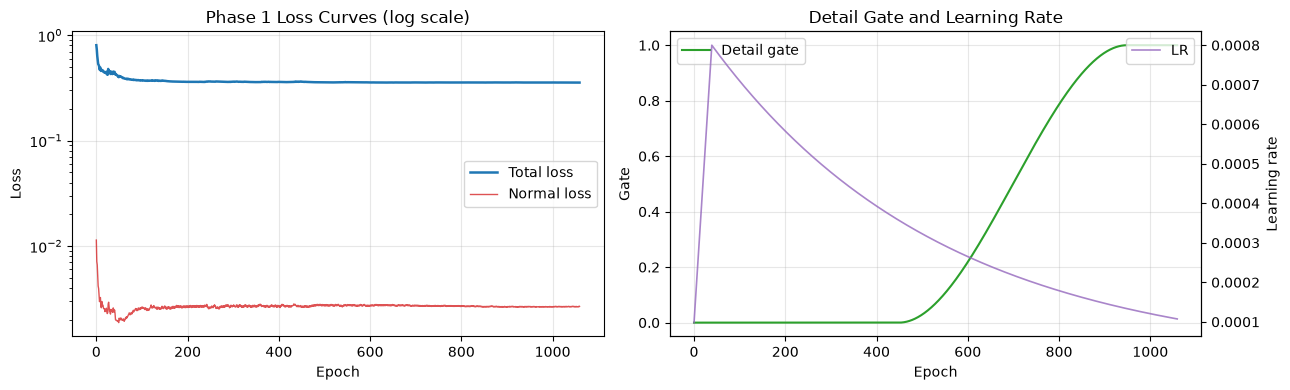

Saved Phase 1 INR weights: /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/phase1_prior_embedding.pth


In [5]:
import math


def build_fixed_subset_indices(
    num_points: int,
    max_points: int,
    seed: int,
    device: torch.device,
) -> torch.Tensor:
    if num_points <= max_points:
        return torch.arange(num_points, device=device, dtype=torch.long)
    g = torch.Generator(device="cpu")
    g.manual_seed(int(seed))
    idx = torch.randperm(num_points, generator=g)[:max_points]
    return idx.to(device=device, dtype=torch.long)


def smoothstep01(x: float) -> float:
    x = max(0.0, min(1.0, float(x)))
    return x * x * (3.0 - 2.0 * x)


def cosine_decay_floor(start: float, floor: float, progress: float) -> float:
    """Cosine decay from start to a strictly positive floor (never zero)."""
    p = max(0.0, min(1.0, float(progress)))
    return float(floor + 0.5 * (start - floor) * (1.0 + math.cos(math.pi * p)))


def set_module_requires_grad(module: torch.nn.Module, enabled: bool) -> None:
    for param in module.parameters():
        param.requires_grad = bool(enabled)


def detail_gate_value(epoch: int, freeze_epochs: int, fade_epochs: int) -> float:
    """Hard 0 during freeze phase, then smooth 0->1 fade of the detail stream."""
    if epoch + 1 <= freeze_epochs:
        return 0.0
    return smoothstep01((epoch + 1 - freeze_epochs) / max(1, fade_epochs))


# NOTE: the model is now a pure-SIREN normal deformer (no positional encoder, no
# internal smoothing, no tangential offset head). Smoothness comes exclusively from
# the explicit regularizers below; coarse-to-fine is enforced by gating the detail
# stream OUTPUT (frequencies are fixed at construction).


# 1) DATA PREPARATION
phase1_base_vertices = prior_vertices_batch.to(device)
# True vertex normals of the prior mesh: INR deformation directions (fixed base mesh).
prior_base_normals = vertex_normals_from_faces(phase1_base_vertices, prior_faces_t).detach()
phase1_target_full = train_template_vertices_batch.to(device)
phase1_target_resampled_np = resample_target_to_prior_directions(
    prior_vertices_np, train_template_vertices_np
)
phase1_target = torch.tensor(
    phase1_target_resampled_np, dtype=torch.float32, device=device
).unsqueeze(0)

# Separate train/eval subsets to stabilize geometry signals.
phase1_target_full_train = build_fixed_subset(phase1_target_full, max_points=1700, seed=SEED + 11)
phase1_target_full_eval = build_fixed_subset(phase1_target_full, max_points=2200, seed=SEED)

# Normal-loss target bank (fixed for stable correspondences).
target_normals_full = vertex_normals_from_faces(
    phase1_target_full, train_template_faces_t
).detach()
target_normal_idx = build_fixed_subset_indices(
    num_points=phase1_target_full.shape[1],
    max_points=min(2400, phase1_target_full.shape[1]),
    seed=SEED + 31,
    device=device,
)
pred_normal_idx = build_fixed_subset_indices(
    num_points=phase1_base_vertices.shape[1],
    max_points=min(2200, phase1_base_vertices.shape[1]),
    seed=SEED + 37,
    device=device,
)
normal_target_vertices = phase1_target_full[:, target_normal_idx, :].detach()
normal_target_normals = target_normals_full[:, target_normal_idx, :].detach()

phase1_base_gap = F.mse_loss(phase1_base_vertices, phase1_target).item()
phase1_full_gap = chamfer_distance(phase1_base_vertices, phase1_target_full_eval).item()
print(f"Phase 1 prior-to-resampled-target MSE before training: {phase1_base_gap:.6f}")
print(f"Phase 1 prior-to-full-asteroid Chamfer before training: {phase1_full_gap:.6f}")
assert phase1_base_gap > 1e-8, "Phase 1 prior base equals asteroid target, which would make training trivial."


# 2) MODEL, OPTIMIZER, AND SMOOTH (NO-RESTART) SCHEDULER
phase1_net = LightcurveToMesh(
    inr_hidden_dim=INR_HIDDEN_DIM,
    inr_num_layers=INR_NUM_LAYERS,
    coarse_w0=15.0,   # lower first-layer frequency for stable global structure
    detail_w0=30.0,
    max_radius_perturb=0.50,
).to(device)
phase1_model = phase1_net
phase1_net.train()

phase1_epochs = 1800
warmup_epochs = 40
final_lr_target = 2.5e-5

phase1_optimizer = torch.optim.AdamW(
    [
        {"params": phase1_net.coarse_deformer.parameters(), "lr": 8.0e-4},
        {"params": phase1_net.detail_deformer.parameters(), "lr": 4.0e-4},
    ],
    betas=(0.9, 0.99),
    weight_decay=8.0e-5,
)

# Smooth monotone LR: linear warmup then exponential decay (no restarts, no jumps).
# Exponential decay drops the LR meaningfully during the coarse phase, unlike a
# very long cosine which keeps LR near max for hundreds of epochs.
exp_gamma = (final_lr_target / 8.0e-4) ** (1.0 / max(1, phase1_epochs - warmup_epochs))
phase1_scheduler = torch.optim.lr_scheduler.SequentialLR(
    phase1_optimizer,
    schedulers=[
        torch.optim.lr_scheduler.LinearLR(
            phase1_optimizer,
            start_factor=0.10,
            end_factor=1.0,
            total_iters=warmup_epochs,
        ),
        torch.optim.lr_scheduler.ExponentialLR(
            phase1_optimizer,
            gamma=exp_gamma,
        ),
    ],
    milestones=[warmup_epochs],
)

# Strict coarse-to-fine gating of the detail stream.
detail_freeze_epochs = 450   # detail output is EXACTLY zero here
detail_fade_epochs = 500     # then fades in smoothly over these epochs

detail_out_scale_base = float(phase1_net.detail_deformer.out_scale)

# Regularization schedule with strictly positive floors (never zero).
LAP_WEIGHT_START, LAP_WEIGHT_FLOOR = 0.14, 0.035
TV_WEIGHT_START, TV_WEIGHT_FLOOR = 0.12, 0.030
EDGE_WEIGHT = 0.10           # constant baseline, never decayed

# Normal loss: reduced and gated by the detail stream to avoid gradient blowups.
NORMAL_WEIGHT_FLOOR, NORMAL_WEIGHT_MAX = 0.10, 0.60
normal_soft_nn_temperature = 35.0

GRAD_CLIP_MAX_NORM = 0.5     # aggressive clipping for SIREN stability

set_module_requires_grad(phase1_net.detail_deformer, False)
detail_unfrozen = False


# 3) TRAINING LOOP: STRICT COARSE-TO-FINE + FLOORED REGULARIZATION
phase1_hist = {
    "total": [],
    "mse": [],
    "iou_train": [],
    "chamfer_train": [],
    "normal_train": [],
    "lap_train": [],
    "tv_train": [],
    "lap_w": [],
    "tv_w": [],
    "normal_w": [],
    "detail_gate": [],
    "lr": [],
}

best_score = -float("inf")
best_iou = -float("inf")
best_chamfer = float("inf")
best_normal = float("inf")
best_mse = float("inf")
best_lap = float("inf")
best_tv = float("inf")
best_epoch = 0
best_state = None
best_detail_gate = 0.0

no_improve_evals = 0
# Never stop before the detail fade has fully completed (plus a settling buffer).
min_epochs_before_stop = detail_freeze_epochs + detail_fade_epochs + 100
early_stop_patience_evals = 26
eval_every = 20
skipped_steps = 0

for epoch in range(phase1_epochs):
    # --- Detail-stream gate: exact zero during freeze, smooth fade afterwards. ---
    detail_gate = detail_gate_value(epoch, detail_freeze_epochs, detail_fade_epochs)
    phase1_net.detail_deformer.out_scale = detail_out_scale_base * detail_gate

    if (not detail_unfrozen) and detail_gate > 0.0:
        set_module_requires_grad(phase1_net.detail_deformer, True)
        detail_unfrozen = True
        print(f"Detail stream fade-in started at epoch {epoch+1}.")

    # --- Floored regularization decay: weights never reach zero. ---
    epoch_progress = epoch / max(1, phase1_epochs - 1)
    lap_weight = cosine_decay_floor(LAP_WEIGHT_START, LAP_WEIGHT_FLOOR, epoch_progress)
    tv_weight = cosine_decay_floor(TV_WEIGHT_START, TV_WEIGHT_FLOOR, epoch_progress)
    normal_weight = NORMAL_WEIGHT_FLOOR + (NORMAL_WEIGHT_MAX - NORMAL_WEIGHT_FLOOR) * detail_gate

    phase1_optimizer.zero_grad(set_to_none=True)
    verts_pred, residual = phase1_net(phase1_base_vertices, prior_base_normals)

    # Data-fit terms.
    target_mse = F.mse_loss(verts_pred, phase1_target)
    target_huber = F.smooth_l1_loss(verts_pred, phase1_target, beta=0.01)

    # Shape terms on full target subset.
    chamfer_train = chamfer_distance(verts_pred, phase1_target_full_train)
    iou_train = differentiable_voxel_measure(
        verts_pred, phase1_target_full_train, R=R_CYLINDER, z_half=1.0, grid_size=16, tau=20.0
    )
    iou_loss = 1.0 - iou_train

    pred_normals = vertex_normals_from_faces(verts_pred, prior_faces_t)
    normal_train = soft_correspondence_normal_loss(
        verts_pred[:, pred_normal_idx, :],
        pred_normals[:, pred_normal_idx, :],
        normal_target_vertices,
        normal_target_normals,
        soft_nn_temperature=normal_soft_nn_temperature,
    )

    # Regularization terms (all with permanent baselines).
    edge_reg = edge_length_regularization(verts_pred, phase1_target, prior_edges_t)
    lap_reg = laplacian_regularization(verts_pred, prior_vertex_neighbors)
    tv_reg = deformation_tv_regularization(verts_pred, phase1_base_vertices, prior_edges_t)

    loss_phase1 = (
        24.0 * target_mse
        + 6.0 * target_huber
        + 2.8 * chamfer_train
        + 3.0 * iou_loss
        + normal_weight * normal_train
        + EDGE_WEIGHT * edge_reg
        + lap_weight * lap_reg
        + tv_weight * tv_reg
    )

    if not torch.isfinite(loss_phase1):
        raise RuntimeError("Phase 1 loss became non-finite. Reduce learning rate.")

    loss_phase1.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(
        phase1_net.parameters(), max_norm=GRAD_CLIP_MAX_NORM
    )
    if torch.isfinite(grad_norm):
        phase1_optimizer.step()
    else:
        skipped_steps += 1
        print(f"Epoch {epoch+1}: non-finite grad norm, step skipped ({skipped_steps} total).")
    phase1_scheduler.step()

    curr_mse = float(target_mse.detach().cpu())
    curr_iou_train = float(iou_train.detach().cpu())
    curr_chamfer_train = float(chamfer_train.detach().cpu())
    curr_normal_train = float(normal_train.detach().cpu())
    curr_lap = float(lap_reg.detach().cpu())
    curr_tv = float(tv_reg.detach().cpu())
    curr_lr = float(phase1_optimizer.param_groups[0]["lr"])

    phase1_hist["total"].append(float(loss_phase1.detach().cpu()))
    phase1_hist["mse"].append(curr_mse)
    phase1_hist["iou_train"].append(curr_iou_train)
    phase1_hist["chamfer_train"].append(curr_chamfer_train)
    phase1_hist["normal_train"].append(curr_normal_train)
    phase1_hist["lap_train"].append(curr_lap)
    phase1_hist["tv_train"].append(curr_tv)
    phase1_hist["lap_w"].append(lap_weight)
    phase1_hist["tv_w"].append(tv_weight)
    phase1_hist["normal_w"].append(normal_weight)
    phase1_hist["detail_gate"].append(detail_gate)
    phase1_hist["lr"].append(curr_lr)

    if (epoch + 1) % eval_every == 0 or epoch == 0:
        with torch.no_grad():
            eval_verts, _ = phase1_net(phase1_base_vertices, prior_base_normals)
            eval_iou = differentiable_voxel_measure(
                eval_verts,
                phase1_target_full_eval,
                R=R_CYLINDER,
                z_half=1.0,
                grid_size=18,
                tau=20.0,
            )
            eval_chamfer = chamfer_distance(eval_verts, phase1_target_full_eval)
            eval_lap = laplacian_regularization(eval_verts, prior_vertex_neighbors)
            eval_tv = deformation_tv_regularization(eval_verts, phase1_base_vertices, prior_edges_t)
            eval_pred_normals = vertex_normals_from_faces(eval_verts, prior_faces_t)
            eval_normal = soft_correspondence_normal_loss(
                eval_verts[:, pred_normal_idx, :],
                eval_pred_normals[:, pred_normal_idx, :],
                normal_target_vertices,
                normal_target_normals,
                soft_nn_temperature=normal_soft_nn_temperature,
            )

        eval_iou_val = float(eval_iou.detach().cpu())
        eval_chamfer_val = float(eval_chamfer.detach().cpu())
        eval_lap_val = float(eval_lap.detach().cpu())
        eval_tv_val = float(eval_tv.detach().cpu())
        eval_normal_val = float(eval_normal.detach().cpu())
        # Fit-driven model selection. Do NOT penalize deformation-TV here: any good
        # fit requires large deformation, so a TV penalty selects the untrained prior.
        eval_score = (
            eval_iou_val
            - 0.20 * eval_chamfer_val
            - 0.12 * eval_normal_val
        )

        print(
            f"Phase1 epoch {epoch+1:04d}/{phase1_epochs} | "
            f"total={phase1_hist['total'][-1]:.6f} | mse={curr_mse:.6f} | "
            f"iou_eval={eval_iou_val:.6f} | ch_eval={eval_chamfer_val:.6f} | "
            f"n_eval={eval_normal_val:.6f} | tv_eval={eval_tv_val:.6f} | "
            f"gate={detail_gate:.2f} | lap_w={lap_weight:.4f} | lr={curr_lr:.2e}"
        )

        if eval_score > best_score + 1e-5:
            best_score = eval_score
            best_iou = eval_iou_val
            best_chamfer = eval_chamfer_val
            best_normal = eval_normal_val
            best_mse = curr_mse
            best_lap = eval_lap_val
            best_tv = eval_tv_val
            best_epoch = epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in phase1_net.state_dict().items()}
            best_detail_gate = detail_gate
            no_improve_evals = 0
        else:
            no_improve_evals += 1

        if (
            (epoch + 1) >= min_epochs_before_stop
            and no_improve_evals >= early_stop_patience_evals
        ):
            print(
                f"Early stopping at epoch {epoch+1}: no eval-score improvement for "
                f"{no_improve_evals} eval checks."
            )
            break


# 4) RESTORE BEST CHECKPOINT (state + detail gate)
if best_state is not None:
    phase1_net.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    phase1_net.detail_deformer.out_scale = detail_out_scale_base * best_detail_gate

phase1_net.eval()
with torch.no_grad():
    phase1_vertices_pred, _ = phase1_net(phase1_base_vertices, prior_base_normals)
    final_eval_iou = differentiable_voxel_measure(
        phase1_vertices_pred,
        phase1_target_full_eval,
        R=R_CYLINDER,
        z_half=1.0,
        grid_size=18,
        tau=20.0,
    )
    final_eval_chamfer = chamfer_distance(phase1_vertices_pred, phase1_target_full_eval)
    final_eval_lap = laplacian_regularization(phase1_vertices_pred, prior_vertex_neighbors)
    final_eval_tv = deformation_tv_regularization(phase1_vertices_pred, phase1_base_vertices, prior_edges_t)
    final_eval_pred_normals = vertex_normals_from_faces(phase1_vertices_pred, prior_faces_t)
    final_eval_normal = soft_correspondence_normal_loss(
        phase1_vertices_pred[:, pred_normal_idx, :],
        final_eval_pred_normals[:, pred_normal_idx, :],
        normal_target_vertices,
        normal_target_normals,
        soft_nn_temperature=normal_soft_nn_temperature,
    )

final_eval_iou_val = float(final_eval_iou.detach().cpu())
final_eval_chamfer_val = float(final_eval_chamfer.detach().cpu())
final_eval_lap_val = float(final_eval_lap.detach().cpu())
final_eval_tv_val = float(final_eval_tv.detach().cpu())
final_eval_normal_val = float(final_eval_normal.detach().cpu())

print(f"Phase 1 best eval IoU: {best_iou:.6f} at epoch {best_epoch} (gate={best_detail_gate:.2f})")
print(f"Phase 1 best eval Chamfer: {best_chamfer:.6f}")
print(f"Phase 1 best eval Normal loss: {best_normal:.6f}")
print(f"Phase 1 best eval Laplacian: {best_lap:.6f}")
print(f"Phase 1 best eval TV: {best_tv:.6f}")
print(f"Phase 1 best target MSE snapshot: {best_mse:.6f}")
print(f"Phase 1 final eval IoU (restored best): {final_eval_iou_val:.6f}")
print(f"Phase 1 final eval Chamfer (restored best): {final_eval_chamfer_val:.6f}")
print(f"Phase 1 final eval Normal loss (restored best): {final_eval_normal_val:.6f}")
print(f"Phase 1 final eval Laplacian (restored best): {final_eval_lap_val:.6f}")
print(f"Phase 1 final eval TV (restored best): {final_eval_tv_val:.6f}")
print(f"Skipped optimizer steps (non-finite grads): {skipped_steps}")
print("Step 3 test: convergence check")
print("Condition: eval IoU > 0.82, eval Chamfer < 0.11, and normal loss < 0.22 indicates strong fit.")
print(
    f"Converged: {(final_eval_iou_val > 0.82) and (final_eval_chamfer_val < 0.11) and (final_eval_normal_val < 0.22)}"
)


# 5) PLOT LOSS, NORMAL TERM, GATE, AND LR
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(phase1_hist["total"], lw=1.8, color="#1f77b4", label="Total loss")
axes[0].plot(phase1_hist["normal_train"], lw=1.0, color="#d62728", alpha=0.8, label="Normal loss")
axes[0].set_yscale("log")
axes[0].set_title("Phase 1 Loss Curves (log scale)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(phase1_hist["detail_gate"], lw=1.5, color="#2ca02c", label="Detail gate")
ax_lr = axes[1].twinx()
ax_lr.plot(phase1_hist["lr"], lw=1.2, color="#9467bd", alpha=0.8, label="LR")
ax_lr.set_ylabel("Learning rate")
axes[1].set_title("Detail Gate and Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Gate")
axes[1].grid(alpha=0.3)
axes[1].legend(loc="upper left")
ax_lr.legend(loc="upper right")
plt.tight_layout()
plt.show()


# 6) SAVE INR CHECKPOINT
phase1_ckpt = Path("phase1_prior_embedding.pth")
torch.save(
    {
        "model_type": "LightcurveToMeshINR-pureSIREN-normal",
        "state_dict": phase1_net.state_dict(),
        "best_iou": best_iou,
        "best_chamfer": best_chamfer,
        "best_normal": best_normal,
        "best_laplacian": best_lap,
        "best_tv": best_tv,
        "best_mse": best_mse,
        "best_epoch": best_epoch,
        "final_eval_iou": final_eval_iou_val,
        "final_eval_chamfer": final_eval_chamfer_val,
        "final_eval_normal": final_eval_normal_val,
        "final_eval_laplacian": final_eval_lap_val,
        "final_eval_tv": final_eval_tv_val,
        "inr_hidden_dim": INR_HIDDEN_DIM,
        "inr_num_layers": INR_NUM_LAYERS,
        "max_radius_perturb": 0.50,
        "detail_gate_at_best": best_detail_gate,
        "detail_out_scale_base": detail_out_scale_base,
        "coarse_w0": float(phase1_net.coarse_deformer.model[0].w0),
        "detail_w0": float(phase1_net.detail_deformer.model[0].w0),
        "phase1_detail_freeze_epochs": detail_freeze_epochs,
        "phase1_detail_fade_epochs": detail_fade_epochs,
        "phase1_lap_weight_start": LAP_WEIGHT_START,
        "phase1_lap_weight_floor": LAP_WEIGHT_FLOOR,
        "phase1_tv_weight_start": TV_WEIGHT_START,
        "phase1_tv_weight_floor": TV_WEIGHT_FLOOR,
        "phase1_edge_weight": EDGE_WEIGHT,
        "phase1_normal_weight_floor": NORMAL_WEIGHT_FLOOR,
        "phase1_normal_weight_max": NORMAL_WEIGHT_MAX,
        "phase1_normal_soft_nn_temperature": normal_soft_nn_temperature,
        "phase1_grad_clip_max_norm": GRAD_CLIP_MAX_NORM,
    },
    phase1_ckpt,
)
print(f"Saved Phase 1 INR weights: {phase1_ckpt.resolve()}")


In [6]:
# 6.1) Attach architecture config metadata for exact checkpoint reconstruction
phase1_ckpt = Path("phase1_prior_embedding.pth")
if not phase1_ckpt.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {phase1_ckpt.resolve()}")

phase1_ckpt_data = torch.load(phase1_ckpt, map_location="cpu")

# Keep these synchronized with LightcurveToMesh(...) settings in the training cell.
# Pure-SIREN normal-deformation model: no encoder matrices, no smoothing, no tangent head.
phase1_ckpt_data["model_type"] = "LightcurveToMeshINR-pureSIREN-normal"
phase1_ckpt_data["max_radius_perturb"] = float(
    phase1_ckpt_data.get("max_radius_perturb", 0.50)
)
phase1_ckpt_data["coarse_w0"] = float(phase1_ckpt_data.get("coarse_w0", 15.0))
phase1_ckpt_data["detail_w0"] = float(phase1_ckpt_data.get("detail_w0", 30.0))

torch.save(phase1_ckpt_data, phase1_ckpt)

print("Updated checkpoint with architecture config:")
for key in (
    "model_type",
    "inr_hidden_dim",
    "inr_num_layers",
    "max_radius_perturb",
    "detail_gate_at_best",
    "coarse_w0",
    "detail_w0",
):
    if key in phase1_ckpt_data:
        print(f"  {key}: {phase1_ckpt_data[key]}")


Updated checkpoint with architecture config:
  model_type: LightcurveToMeshINR-pureSIREN-normal
  inr_hidden_dim: 256
  inr_num_layers: 8
  max_radius_perturb: 0.5
  detail_gate_at_best: 0.0
  coarse_w0: 15.0
  detail_w0: 30.0


In [7]:
# 7) FINAL RESULT VISUALIZATION (interactive rotatable 3D, as in inr_forward_train.ipynb)
required_vars = [
    "phase1_base_vertices",
    "phase1_vertices_pred",
    "phase1_target_full",
    "prior_faces_np",
    "train_template_faces_np",
]
missing_vars = [name for name in required_vars if name not in globals()]
if missing_vars:
    raise RuntimeError(
        "Run the training cell first. Missing variables: " + ", ".join(missing_vars)
    )

phase1_template_np = phase1_base_vertices[0].detach().cpu().numpy()
phase1_vertices_np = phase1_vertices_pred[0].detach().cpu().numpy()
phase1_target_full_np = phase1_target_full[0].detach().cpu().numpy()

fig_input_prior = plot_interactive_mesh(
    vertices=phase1_template_np,
    faces=prior_faces_np,
    title="Input Prior",
    mesh_color="#73b7ff",
    show_edges=False,
)
fig_input_prior.show()

fig_predicted = plot_interactive_mesh(
    vertices=phase1_vertices_np,
    faces=prior_faces_np,
    title=(
        f"Predicted Mesh (best epoch {best_epoch}, "
        f"IoU={final_eval_iou_val:.3f}, Chamfer={final_eval_chamfer_val:.4f})"
    ),
    mesh_color="#ffb86b",
    show_edges=False,
)
fig_predicted.show()

fig_target = plot_interactive_mesh(
    vertices=phase1_target_full_np,
    faces=train_template_faces_np,
    title="Target Mesh (GT template)",
    mesh_color="#4c72b0",
    show_edges=False,
)
fig_target.show()
